# Adversarial Search: Solving Tic-Tac-Toe with Pure Monte Carlo Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* Pure Monte Carlo search

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

%precision 3

'%.3f'

# Pure Monte Carlo Search

See AIMA page 161ff. 

We implement a extremely simplified version.

For the current state: 
1. Simulate $N$ random playouts for each possible action and 
2. pick the action with the highest average utility.

__Important note:__ we use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with
1. a good __playout policy__ (e.g., learned by self-play) and 
2. a __selection strategy__ (e.g., UCB1).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: return(u)
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


# Playout for action 0 (top-left corner)
board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

0
0
-1
1
1


In [4]:
def playouts(board, action, player = 'x', N = 100):
    """Perform N playouts following the given action for the given board."""
    return [ playout(board, action, player) for i in range(N) ]

u = playouts(board, 0)
print("Playout results:", u)

print(f"mean utility: {np.mean(u)}")

p_win = sum(np.array(u) == +1)/len(u)
p_loss = sum(np.array(u) == -1)/len(u)
p_draw = sum(np.array(u) == 0)/len(u)
print(f"win probability: {p_win}")
print(f"loss probability: {p_loss}")
print(f"draw probability: {p_draw}")

Playout results: [-1, 1, 0, 0, 1, 1, 1, -1, 0, -1, -1, 1, 1, 1, -1, 1, 1, 1, -1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, -1, 1, 1, 0, 0, 1, 1, 1, 1, 1, -1, -1, 1, 1, -1, 1, 1, 1, 1, 1, -1, 1, -1, -1, -1, 1, 1, 1, 1, 1, 1, -1, 1, 1, 0, 1, 1, 1, 1, 1, 1, -1, 1, 1, 1, 1, 1, -1, 0, 1, -1, -1, 1, 1, -1, 1, 0, -1, 1, 1, 0, 1, -1, -1, 1, -1, 1, -1, 0, 0]
mean utility: 0.37
win probability: 0.63
loss probability: 0.26
draw probability: 0.11


__Note:__ This shows that the player who goes first has a significant advantage in __pure random play.__ Real players do not play randomly, a better playout policy would be good.

## Pure Monte Carlo Search

In [5]:
import math

DEBUG = 1


def pmcs(board, N = 100, player = 'x'):
    """Pure Monte Carlo Search. Returns the action that has the largest average utility.
    The N playouts are evenly divided between the possible actions."""
    global DEBUG
    
    acts = actions(board)
    n = math.floor(N/len(acts))
    if DEBUG >= 1: print(f"Actions: {acts} ({N} total playouts = {n} playouts per action)")
    
    ps = { i : np.mean(playouts(board, i, player, N = n)) for i in acts }
    if DEBUG >= 1: display(ps)
        
    action = max(ps, key=ps.get)
    return action

board = empty_board()
display(board)
%time print(pmcs(board))

print()
print("10000 playouts give a better utility estimate.")
%time print(pmcs(board, N = 10000))

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (100 total playouts = 11 playouts per action)


{0: 0.455,
 1: 0.364,
 2: 0.545,
 3: 0.091,
 4: 0.909,
 5: 0.455,
 6: 0.818,
 7: -0.273,
 8: 0.091}

4
CPU times: total: 15.6 ms
Wall time: 23.5 ms

10000 playouts give a better utility estimate.
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10000 total playouts = 1111 playouts per action)


{0: 0.268,
 1: 0.191,
 2: 0.357,
 3: 0.229,
 4: 0.478,
 5: 0.221,
 6: 0.353,
 7: 0.200,
 8: 0.325}

4
CPU times: total: 2.03 s
Wall time: 2.1 s


Looks like the center and the corners are a lot better.

## Some Tests

### x is about to win (play 8)


Board:


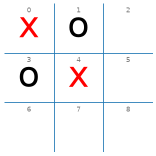


Actions: [2, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{2: 0.800, 5: 0.650, 6: 0.800, 7: 0.550, 8: 1.000}

8

CPU times: total: 15.6 ms
Wall time: 12.4 ms


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### o is about to win

Board:


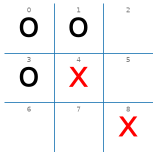


Actions: [2, 5, 6, 7] (100 total playouts = 25 playouts per action)


{2: 0.120, 5: -0.680, 6: -0.120, 7: -0.840}

2

CPU times: total: 15.6 ms
Wall time: 8.82 ms

Actions: [2, 5, 6, 7] (1000 total playouts = 250 playouts per action)


{2: 0.064, 5: -0.672, 6: 0.032, 7: -0.528}

2

CPU times: total: 31.2 ms
Wall time: 64.5 ms


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

print()
%time display(pmcs(board, N = 1000))

### x can draw if it chooses 7

Board:


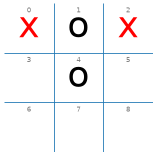


Actions: [3, 5, 6, 7, 8] (100 total playouts = 20 playouts per action)


{3: 0.050, 5: -0.150, 6: -0.200, 7: 0.050, 8: -0.400}

3

CPU times: total: 31.2 ms
Wall time: 13.8 ms


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

### Empty board: Only a draw an be guaranteed

Board:


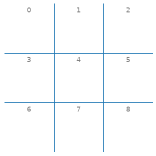


Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (5000 total playouts = 555 playouts per action)


{0: 0.398,
 1: 0.124,
 2: 0.378,
 3: 0.231,
 4: 0.452,
 5: 0.272,
 6: 0.348,
 7: 0.155,
 8: 0.342}

4

CPU times: total: 953 ms
Wall time: 1.06 s


In [9]:
board = empty_board() 

print("Board:")
show_board(board)

print()
%time display(pmcs(board, N = 5000))

### A bad situation

Board:


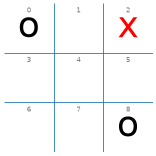


Actions: [1, 3, 4, 5, 6, 7] (100 total playouts = 16 playouts per action)


{1: -1.000, 3: -0.688, 4: 0.125, 5: -0.625, 6: -0.375, 7: -0.312}

4

CPU times: total: 15.6 ms
Wall time: 11.7 ms


In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(pmcs(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def pmcs10_player(board, player = 'x'):
    action = pmcs(board, N = 10, player = player)
    return action

def pmcs100_player(board, player = 'x'):
    action = pmcs(board, N = 100, player = player)
    return action

def pmcs1000_player(board, player = 'x'):
    action = pmcs(board, N = 1000, player = player)
    return action


DEBUG = 1
print("PMCS vs. random:")
display(play(pmcs10_player, random_player, N = 1))

PMCS vs. random:
Actions: [0, 1, 2, 3, 4, 5, 6, 7, 8] (10 total playouts = 1 playouts per action)


{0: 1.000,
 1: 1.000,
 2: 1.000,
 3: 1.000,
 4: -1.000,
 5: 1.000,
 6: -1.000,
 7: 1.000,
 8: 1.000}

Actions: [1, 2, 3, 4, 5, 6, 7] (10 total playouts = 1 playouts per action)


{1: 0.000, 2: 1.000, 3: -1.000, 4: 1.000, 5: 0.000, 6: 1.000, 7: 0.000}

Actions: [1, 3, 5, 6, 7] (10 total playouts = 2 playouts per action)


{1: 1.000, 3: 0.500, 5: -0.500, 6: 0.000, 7: 0.500}

{'x': 1, 'o': 0, 'd': 0}

In [12]:
import time
DEBUG = 0

print("PMCS (10) vs. random:")
t0 = time.perf_counter()
res_10_x = play(pmcs10_player, random_player)
time_10_x = time.perf_counter() - t0
display(res_10_x)

print("\nrandom vs. PMCS (10):")
t0 = time.perf_counter()
res_10_o = play(random_player, pmcs10_player)
time_10_o = time.perf_counter() - t0
display(res_10_o)

PMCS (10) vs. random:


{'x': 90, 'o': 9, 'd': 1}


random vs. PMCS (10):


{'x': 18, 'o': 68, 'd': 14}

In [13]:
DEBUG = 0

print("PMCS (100) vs. random:")
t0 = time.perf_counter()
res_100_x = play(pmcs100_player, random_player)
time_100_x = time.perf_counter() - t0
display(res_100_x)

print("\nrandom vs. PMCS (100):")
t0 = time.perf_counter()
res_100_o = play(random_player, pmcs100_player)
time_100_o = time.perf_counter() - t0
display(res_100_o)

PMCS (100) vs. random:


{'x': 99, 'o': 0, 'd': 1}


random vs. PMCS (100):


{'x': 8, 'o': 88, 'd': 4}

In [14]:
DEBUG = 0
print("PMCS (100) vs. PMCS (10):")
%time display(play(pmcs100_player, pmcs10_player))

print()
print("PMCS (10) vs. PMCS (100)")
%time display(play(pmcs10_player, pmcs100_player))

PMCS (100) vs. PMCS (10):


{'x': 86, 'o': 1, 'd': 13}

CPU times: total: 4.59 s
Wall time: 4.64 s

PMCS (10) vs. PMCS (100)


{'x': 35, 'o': 50, 'd': 15}

CPU times: total: 3.7 s
Wall time: 3.72 s


In [15]:
DEBUG = 0

print("PMCS (1000) vs. random:")
t0 = time.perf_counter()
res_1000_x = play(pmcs1000_player, random_player)
time_1000_x = time.perf_counter() - t0
display(res_1000_x)

print("\nrandom vs. PMCS (1000):")
t0 = time.perf_counter()
res_1000_o = play(random_player, pmcs1000_player)
time_1000_o = time.perf_counter() - t0
display(res_1000_o)

PMCS (1000) vs. random:


{'x': 100, 'o': 0, 'd': 0}


random vs. PMCS (1000):


{'x': 3, 'o': 92, 'd': 5}

**Note 1:** You can try `pmcs_1000`, but it will take a few minutes to run 100 games.

**Note 2:** The important advantage about Monte Carlo Search is that we do not need to define a heuristic evaluation function to decide what boards are good.

## Kết quả thực nghiệm – Bài 5: Pure Monte Carlo Search

Bảng kết quả thực nghiệm được tổng hợp và tính toán tự động bằng mã nguồn Python (`pandas.DataFrame`) từ các biến kết quả thực nghiệm qua 2 lượt đối đầu (100 ván đi trước X và 100 ván đi sau O):

In [16]:
import pandas as pd

pd.set_option('display.max_colwidth', None)

def calc_stats(res_x, res_o, t_x, t_o, note):
    total_games = 200
    wins = res_x['x'] + res_o['o']
    draws = res_x['d'] + res_o['d']
    losses = res_x['o'] + res_o['x']
    total_time = t_x + t_o
    # Ước lượng trung bình PMCS đi ~3 nước mỗi ván (600 nước / 200 ván)
    avg_ms_per_move = (total_time / 600) * 1000

    return {
        "Tỷ lệ thắng (PMCS)": f"{(wins / total_games) * 100:.1f}%",
        "Tỷ lệ hòa": f"{(draws / total_games) * 100:.1f}%",
        "Tỷ lệ thua (PMCS)": f"{(losses / total_games) * 100:.1f}%",
        "Thời gian TB / nước đi": f"~{avg_ms_per_move:.1f} ms",
        "Nhận xét": note
    }

data_bai5 = {
    10: calc_stats(res_10_x, res_10_o, time_10_x, time_10_o,
                   f"Thắng khi đi trước ({res_10_x['x']}%), đi sau thua {res_10_o['x']}% do N nhỏ, phương sai cao"),
    100: calc_stats(res_100_x, res_100_o, time_100_x, time_100_o,
                    f"Ổn định cao, đi trước thắng {res_100_x['x']}%, đi sau thắng {res_100_o['o']}%"),
    1000: calc_stats(res_1000_x, res_1000_o, time_1000_x, time_1000_o,
                     f"Độ chính xác cao nhất (thắng {res_1000_x['x']}% đi trước, {res_1000_o['o']}% đi sau), thời gian chạy tăng x10")
}

df_bai5 = pd.DataFrame.from_dict(data_bai5, orient="index")
df_bai5.index.name = "Số playout N"

print("=== BẢNG KẾT QUẢ THỰC NGHIỆM – BÀI 5: PURE MONTE CARLO SEARCH ===")
display(df_bai5)

=== BẢNG KẾT QUẢ THỰC NGHIỆM – BÀI 5: PURE MONTE CARLO SEARCH ===


,Tỷ lệ thắng (PMCS),Tỷ lệ hòa,Tỷ lệ thua (PMCS),Thời gian TB / nước đi,Nhận xét
Số playout N,,,,,
10,79.0%,7.5%,13.5%,~1.2 ms,"Thắng khi đi trước (90%), đi sau thua 18% do N nhỏ, phương sai cao"
100,93.5%,2.5%,4.0%,~13.6 ms,"Ổn định cao, đi trước thắng 99%, đi sau thắng 88%"
1000,96.0%,2.5%,1.5%,~128.9 ms,"Độ chính xác cao nhất (thắng 100% đi trước, 92% đi sau), thời gian chạy tăng x10"


## Bảng 4. Tổng hợp và báo cáo kết quả (Bài 5 – Pure Monte Carlo Search)

Bảng 4 tổng hợp các lượt đối đầu giữa Pure Monte Carlo Search và Random (cột Thắng/Hòa/Thua tính theo góc nhìn của tác tử đi trước X), được tạo tự động bằng mã nguồn Python:

In [17]:
records_tonghop = [
    {
        "Tác tử / Thuật toán": "Pure Monte Carlo (N=10)", "Đối thủ": "Random", "Số ván": 100,
        "Thắng": res_10_x['x'], "Hòa": res_10_x['d'], "Thua": res_10_x['o'],
        "Thời gian TB / nước đi": f"~{(time_10_x / 300) * 1000:.1f} ms"
    },
    {
        "Tác tử / Thuật toán": "Random", "Đối thủ": "Pure Monte Carlo (N=10)", "Số ván": 100,
        "Thắng": res_10_o['x'], "Hòa": res_10_o['d'], "Thua": res_10_o['o'],
        "Thời gian TB / nước đi": f"~{(time_10_o / 300) * 1000:.1f} ms"
    },
    {
        "Tác tử / Thuật toán": "Pure Monte Carlo (N=100)", "Đối thủ": "Random", "Số ván": 100,
        "Thắng": res_100_x['x'], "Hòa": res_100_x['d'], "Thua": res_100_x['o'],
        "Thời gian TB / nước đi": f"~{(time_100_x / 300) * 1000:.1f} ms"
    },
    {
        "Tác tử / Thuật toán": "Random", "Đối thủ": "Pure Monte Carlo (N=100)", "Số ván": 100,
        "Thắng": res_100_o['x'], "Hòa": res_100_o['d'], "Thua": res_100_o['o'],
        "Thời gian TB / nước đi": f"~{(time_100_o / 300) * 1000:.1f} ms"
    },
    {
        "Tác tử / Thuật toán": "Pure Monte Carlo (N=1000)", "Đối thủ": "Random", "Số ván": 100,
        "Thắng": res_1000_x['x'], "Hòa": res_1000_x['d'], "Thua": res_1000_x['o'],
        "Thời gian TB / nước đi": f"~{(time_1000_x / 300) * 1000:.1f} ms"
    },
    {
        "Tác tử / Thuật toán": "Random", "Đối thủ": "Pure Monte Carlo (N=1000)", "Số ván": 100,
        "Thắng": res_1000_o['x'], "Hòa": res_1000_o['d'], "Thua": res_1000_o['o'],
        "Thời gian TB / nước đi": f"~{(time_1000_o / 300) * 1000:.1f} ms"
    }
]

df_tonghop = pd.DataFrame(records_tonghop)
print("=== BẢNG 4. TỔNG HỢP VÀ BÁO CÁO KẾT QUẢ (PURE MONTE CARLO SEARCH) ===")
display(df_tonghop)

=== BẢNG 4. TỔNG HỢP VÀ BÁO CÁO KẾT QUẢ (PURE MONTE CARLO SEARCH) ===


,Tác tử / Thuật toán,Đối thủ,Số ván,Thắng,Hòa,Thua,Thời gian TB / nước đi
0,Pure Monte Carlo (N=10),Random,100,90,1,9,~1.4 ms
1,Random,Pure Monte Carlo (N=10),100,18,14,68,~1.1 ms
2,Pure Monte Carlo (N=100),Random,100,99,1,0,~15.4 ms
3,Random,Pure Monte Carlo (N=100),100,8,4,88,~11.9 ms
4,Pure Monte Carlo (N=1000),Random,100,100,0,0,~140.8 ms
5,Random,Pure Monte Carlo (N=1000),100,3,5,92,~116.9 ms
